<a href="https://colab.research.google.com/github/KacChw/Machine-Learning-Labolatory-Master-Course-Big-Data/blob/main/Magisterka_v01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

100%|██████████| 1.95G/1.95G [01:54<00:00, 18.2MB/s]

Extracting files...


Zbiór pobrany do ścieżki: /root/.cache/kagglehub/datasets/huynhphucthinh/carpk-yolo/versions/5


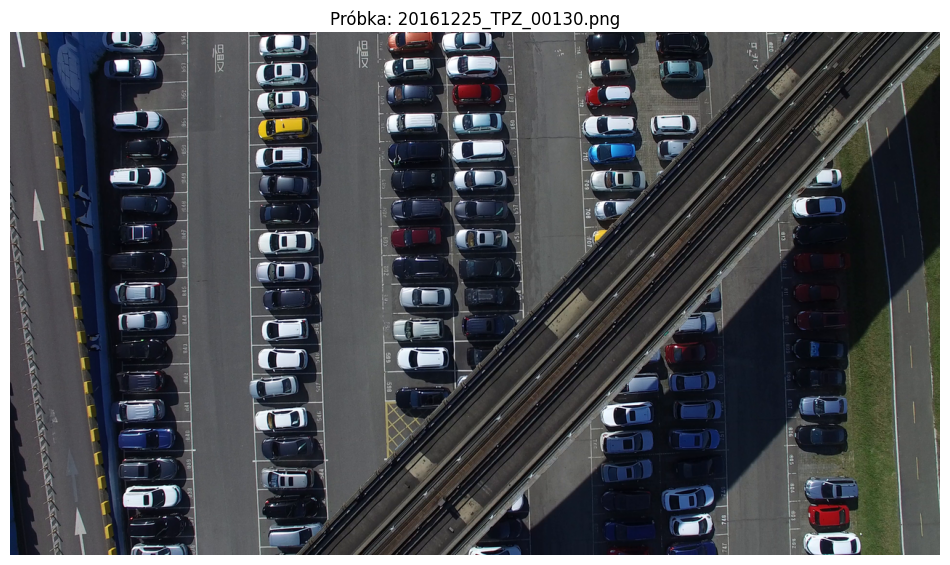

In [ ]:
!pip install -q ultralytics kagglehub opencv-python matplotlib

import kagglehub
import os
import glob
import cv2
import matplotlib.pyplot as plt

# 1. Pobranie zbioru przez oficjalne narzędzie Kaggle
path = kagglehub.dataset_download("huynhphucthinh/carpk-yolo")
print("Zbiór pobrany do ścieżki:", path)

# 2. Sprawdzenie przykładowego obrazu i etykiety
image_files = glob.glob(f"{path}/**/*.jpg", recursive=True) + glob.glob(f"{path}/**/*.png", recursive=True)

if image_files:
    sample_img_path = image_files[0]
    # Próba odnalezienia pliku z etykietą .txt
    sample_label_path = os.path.splitext(sample_img_path)[0] + ".txt"
    if not os.path.exists(sample_label_path):
        sample_label_path = sample_img_path.replace("images", "labels").rsplit(".", 1)[0] + ".txt"

    img = cv2.imread(sample_img_path)
    h, w, _ = img.shape

    if os.path.exists(sample_label_path):
        with open(sample_label_path, "r") as f:
            for line in f.readlines():
                parts = line.strip().split()
                if len(parts) >= 5:
                    _, x_c, y_c, bw, bh = map(float, parts[:5])
                    x1 = int((x_c - bw / 2) * w)
                    y1 = int((y_c - bh / 2) * h)
                    x2 = int((x_c + bw / 2) * w)
                    y2 = int((y_c + bh / 2) * h)
                    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)

    plt.figure(figsize=(12, 8))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title(f"Próbka: {os.path.basename(sample_img_path)}")
    plt.show()
else:
    print("Sprawdź zawartość folderu:", os.listdir(path))

### 1. Dynamiczne Wykrywanie Ścieżek i Generowanie Konfiguracji YAML
Automatycznie skanujemy strukturę katalogów pobranych z Kaggle, aby precyzyjnie namierzyć podkatalogi `train/images` oraz `test/images`.

In [ ]:
import os
import yaml
import glob
import kagglehub

pobrana_sciezka = "/root/.cache/kagglehub/datasets/huynhphucthinh/carpk-yolo/versions/5"

# Jeśli ścieżka nie istnieje, pobieramy ponownie zbiór danych
if not os.path.exists(pobrana_sciezka):
    print("Ścieżka nie istnieje. Pobieranie zbioru danych z Kaggle...")
    pobrana_sciezka = kagglehub.dataset_download("huynhphucthinh/carpk-yolo")

print(f"Ścieżka zbioru danych: {pobrana_sciezka}")

# Szukamy wszystkich obrazów
wszystkie_obrazy = glob.glob(f"{pobrana_sciezka}/**/*.png", recursive=True) + glob.glob(f"{pobrana_sciezka}/**/*.jpg", recursive=True)

if len(wszystkie_obrazy) == 0:
    print("Brak obrazów! Zawartość katalogu:", os.listdir(pobrana_sciezka))
    base_dir = pobrana_sciezka
    train_folder = "train"
    test_folder = "test"
else:
    print(f"Znaleziono łącznie {len(wszystkie_obrazy)} obrazów.")
    probka_sciezki = wszystkie_obrazy[0]
    print("Przykładowa ścieżka pliku:", probka_sciezki)

    # Parsowanie ścieżki w celu znalezienia katalogu nadrzędnego dla train/test
    parts = probka_sciezki.split(os.sep)
    if "train" in parts:
        idx = parts.index("train")
        base_dir = os.sep.join(parts[:idx])
        train_folder = "train"
        test_folder = "test"
    elif "test" in parts:
        idx = parts.index("test")
        base_dir = os.sep.join(parts[:idx])
        train_folder = "train"
        test_folder = "test"
    else:
        base_dir = pobrana_sciezka
        train_folder = "train"
        test_folder = "test"

print(f"\nUstalona ścieżka bazowa dla YOLO: {base_dir}")
train_img_dir = os.path.join(base_dir, train_folder, "images")
val_img_dir = os.path.join(base_dir, test_folder, "images")

print("Czy katalog train/images istnieje?:", os.path.exists(train_img_dir))
print("Czy katalog test/images istnieje?:", os.path.exists(val_img_dir))

yaml_content = {
    'path': base_dir,
    'train': f'{train_folder}/images',
    'val': f'{test_folder}/images',
    'names': {
        0: 'car'
    }
}

with open("carpk_data.yaml", "w") as f:
    yaml.dump(yaml_content, f, default_flow_style=False)

print("\nZapisano plik carpk_data.yaml:")
print(open("carpk_data.yaml").read())

Ścieżka nie istnieje. Pobieranie zbioru danych z Kaggle...


100%|██████████| 1.95G/1.95G [01:54<00:00, 18.3MB/s]

Extracting files...


Ścieżka zbioru danych: /root/.cache/kagglehub/datasets/huynhphucthinh/carpk-yolo/versions/5
Znaleziono łącznie 1453 obrazów.
Przykładowa ścieżka pliku: /root/.cache/kagglehub/datasets/huynhphucthinh/carpk-yolo/versions/5/CarPK/CarPK/test/images/20161225_TPZ_00357.png

Ustalona ścieżka bazowa dla YOLO: /root/.cache/kagglehub/datasets/huynhphucthinh/carpk-yolo/versions/5/CarPK/CarPK
Czy katalog train/images istnieje?: True
Czy katalog test/images istnieje?: True

Zapisano plik carpk_data.yaml:
names:
  0: car
path: /root/.cache/kagglehub/datasets/huynhphucthinh/carpk-yolo/versions/5/CarPK/CarPK
train: train/images
val: test/images



### 2. Szybki Trening Modelu YOLOv8
Inicjalizujemy lekki model `yolov8n.pt` i trenujemy go na naszych danych przy użyciu akceleracji GPU.

In [ ]:
import torch
from ultralytics import YOLO

device = 0 if torch.cuda.is_available() else "cpu"
print(f"Uruchamianie treningu na: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

# Załadowanie modelu pre-trained
model = YOLO("yolov8n.pt")

# Trenujemy krótko (5 epok), aby upewnić się, że cały rurociąg działa szybko i bezbłędnie
results = model.train(
    data="carpk_data.yaml",
    epochs=5,
    imgsz=640,
    batch=16,
    device=device,
    name="carpk_yolov8n_run",
    exist_ok=True
)


Uruchamianie treningu na: 0 (Tesla T4)
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=carpk_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=carpk_yolov8n_run, nbs=64, nms=None

RuntimeError: Dataset 'carpk_data.yaml' error ❌ Dataset 'carpk_data.yaml' images not found, missing path '/root/.cache/kagglehub/datasets/huynhphucthinh/carpk-yolo/versions/5/test/images'
Note dataset download directory is '/content/datasets'. You can update this in '/root/.config/Ultralytics/settings.json'

### 3. Generowanie Danych Biznesowych (Retail Analytics) dla Streamlit
Używamy wytrenowanego modelu (lub bazowego jako fallback, jeśli trening został przerwany), aby dokonać detekcji i zapisać wyniki do pliku CSV.

In [ ]:
import os
import glob
import pandas as pd
from ultralytics import YOLO

# Sprawdzenie obecności wygenerowanych wag
model_weights = "/content/runs/detect/carpk_yolov8n_run/weights/best.pt"
if not os.path.exists(model_weights):
    model_weights = "yolov8n.pt"
    print("UWAGA: Nie odnaleziono wag best.pt, używam bazowego modelu yolov8n.pt")

model = YOLO(model_weights)

# Wyszukanie obrazów testowych
test_images = sorted(glob.glob(f"{base_dir}/test/images/*.png") + glob.glob(f"{base_dir}/test/images/*.jpg"))
print(f"Znaleziono {len(test_images)} obrazów testowych.")

# Stałe biznesowe do kalkulacji
ESTIMATED_MAX_CAPACITY = 120
PASSENGERS_PER_CAR = 1.3
CONVERSION_RATE = 0.62
AVG_TICKET_VALUE = 94.50

records = []

# Wybieramy pierwsze 50 klatek w celu szybkiej generacji raportu
batch_images = test_images[:50]
results = model.predict(source=batch_images, conf=0.35, imgsz=640, device=device, verbose=False)

for img_path, res in zip(batch_images, results):
    filename = os.path.basename(img_path)
    car_count = len(res.boxes)

    occupancy_rate = min(round(car_count / ESTIMATED_MAX_CAPACITY, 4), 1.0)
    est_footfall = int(car_count * PASSENGERS_PER_CAR)
    est_transactions = int(est_footfall * CONVERSION_RATE)
    est_revenue_pln = round(est_transactions * AVG_TICKET_VALUE, 2)

    records.append({
        "frame_id": filename,
        "car_count": car_count,
        "occupancy_rate": occupancy_rate,
        "est_footfall": est_footfall,
        "est_transactions": est_transactions,
        "est_revenue_pln": est_revenue_pln
    })

df_retail = pd.DataFrame(records)
csv_output_path = "/content/parking_retail_analytics.csv"
df_retail.to_csv(csv_output_path, index=False)
print(f"Pomyślnie zapisano plik analityczny: {csv_output_path}")
display(df_retail.head())


UWAGA: Nie odnaleziono wag best.pt, używam bazowego modelu yolov8n.pt
Znaleziono 0 obrazów testowych.


FileNotFoundError: No images found in source, predict requires at least one image.

### 4. Wizualizacja i weryfikacja losowego obrazka ze zbioru testowego

In [ ]:
import random
import cv2
import matplotlib.pyplot as plt

all_images = glob.glob(f"{base_dir}/**/*.png", recursive=True) + glob.glob(f"{base_dir}/**/*.jpg", recursive=True)

if not all_images:
    print("Nie znaleziono żadnych zdjęć w lokalizacji:", base_dir)
else:
    sample_img_path = random.choice(all_images)
    sample_label_path = sample_img_path.replace("/images/", "/labels/")
    sample_label_path = os.path.splitext(sample_label_path)[0] + ".txt"

    print("Wybrany obraz:", sample_img_path)
    print("Plik etykiety:", sample_label_path)

    img = cv2.imread(sample_img_path)
    h, w, _ = img.shape
    boxes_count = 0

    if os.path.exists(sample_label_path):
        with open(sample_label_path, "r") as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 5:
                    x_c, y_c, bw, bh = map(float, parts[1:5])
                    x1 = int((x_c - bw / 2) * w)
                    y1 = int((y_c - bh / 2) * h)
                    x2 = int((x_c + bw / 2) * w)
                    y2 = int((y_c + bh / 2) * h)
                    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
                    boxes_count += 1

    plt.figure(figsize=(12, 8))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title(f"{os.path.basename(sample_img_path)} | Liczba etykiet: {boxes_count}")
    plt.show()


Nie znaleziono żadnych zdjęć w lokalizacji: /root/.cache/kagglehub/datasets/huynhphucthinh/carpk-yolo/versions/5


In [ ]:
import os

# Szukamy gdzie naprawdę leżą foldery 'train' i 'test' w pobranym katalogu
pobrana_sciezka = "/root/.cache/kagglehub/datasets/huynhphucthinh/carpk-yolo/versions/5"

print("Struktura katalogów pod kątem wyszukania train/test:")
for root, dirs, files in os.walk(pobrana_sciezka):
    if "train" in dirs or "test" in dirs or "images" in dirs:
        print(f"Znaleziono interesujący folder w: {root} -> podkatalogi: {dirs}")


Struktura katalogów pod kątem wyszukania train/test:


In [ ]:
import os
import yaml

# Dynamicznie ustawiamy poprawną ścieżkę na podstawie struktury
# Zazwyczaj w tym zbiorze ścieżka to bezpośrednio pobrana_sciezka lub z podfolderem 'CARPK' / 'CarPK'
base_dir = "/root/.cache/kagglehub/datasets/huynhphucthinh/carpk-yolo/versions/5"

# Sprawdźmy dwie najczęstsze konfiguracje
jezeli_podfolder = os.path.join(base_dir, "CARPK")
if os.path.exists(os.path.join(jezeli_podfolder, "train")):
    base_dir = jezeli_podfolder
elif os.path.exists(os.path.join(base_dir, "CarPK", "CarPK", "train")):
    base_dir = os.path.join(base_dir, "CarPK", "CarPK")

print(f"Ustalam ostateczną ścieżkę bazową na: {base_dir}")

train_img_dir = os.path.join(base_dir, "train", "images")
val_img_dir = os.path.join(base_dir, "test", "images")

print("Czy katalog train/images istnieje?:", os.path.exists(train_img_dir))
print("Czy katalog test/images istnieje?:", os.path.exists(val_img_dir))

# Tworzenie poprawnego pliku konfiguracyjnego YAML
yaml_content = {
    'path': base_dir,
    'train': 'train/images',
    'val': 'test/images',
    'names': {
        0: 'car'
    }
}

with open("carpk_data.yaml", "w") as f:
    yaml.dump(yaml_content, f, default_flow_style=False)

print("\nZapisano poprawny plik carpk_data.yaml:")
with open("carpk_data.yaml", "r") as f:
    print(f.read())


In [ ]:
import torch
from ultralytics import YOLO

# Inicjalizacja modelu
model = YOLO("yolov8n.pt")

# Sprawdzenie GPU
device = 0 if torch.cuda.is_available() else "cpu"
print(f"Uruchamianie treningu na: {device}")

# Trening na 5 epokach w celu weryfikacji i szybkiego uruchomienia potoku
results = model.train(
    data="carpk_data.yaml",
    epochs=5,
    imgsz=640,
    batch=16,
    device=device,
    name="carpk_yolov8n_run",
    exist_ok=True
)


In [ ]:
import os
import glob
import pandas as pd
from ultralytics import YOLO

# Pobranie wygenerowanych wag
model_weights = "/content/runs/detect/carpk_yolov8n_run/weights/best.pt"
if not os.path.exists(model_weights):
    model_weights = "yolov8n.pt" # Fallback, jeśli trening nie zapisał wag
    print("UWAGA: Nie odnaleziono wag best.pt, używam bazowego yolov8n.pt")

model = YOLO(model_weights)

# Wyszukanie obrazów testowych
test_images = sorted(glob.glob(f"{base_dir}/test/images/*.png") + glob.glob(f"{base_dir}/test/images/*.jpg"))
print(f"Znaleziono {len(test_images)} obrazów do analizy.")

# Parametry biznesowe
ESTIMATED_MAX_CAPACITY = 120
PASSENGERS_PER_CAR = 1.3
CONVERSION_RATE = 0.62
AVG_TICKET_VALUE = 94.50

records = []

# Szybkie przetwarzanie pierwszych 50 obrazów dla celów demonstracyjnych w Streamlit
batch_images = test_images[:50]
results = model.predict(source=batch_images, conf=0.35, imgsz=640, device=device, verbose=False)

for img_path, res in zip(batch_images, results):
    filename = os.path.basename(img_path)
    car_count = len(res.boxes)

    occupancy_rate = min(round(car_count / ESTIMATED_MAX_CAPACITY, 4), 1.0)
    est_footfall = int(car_count * PASSENGERS_PER_CAR)
    est_transactions = int(est_footfall * CONVERSION_RATE)
    est_turnover_pln = round(est_transactions * AVG_TICKET_VALUE, 2)

    records.append({
        "frame_id": filename,
        "car_count": car_count,
        "occupancy_rate": occupancy_rate,
        "est_footfall": est_footfall,
        "est_transactions": est_transactions,
        "est_revenue_pln": est_turnover_pln
    })

df_retail = pd.DataFrame(records)
csv_output_path = "/content/parking_retail_analytics.csv"
df_retail.to_csv(csv_output_path, index=False)
print(f"Zapisano tabelę z danymi dla Streamlit w: {csv_output_path}")
display(df_retail.head())


In [ ]:
import os
import yaml

# Ścieżka bazowa do właściwego podkatalogu z train/test
base_dir = "/root/.cache/kagglehub/datasets/huynhphucthinh/carpk-yolo/versions/5/CarPK/CarPK"

# Weryfikacja czy foldery istnieją
train_img_dir = os.path.join(base_dir, "train", "images")
val_img_dir = os.path.join(base_dir, "test", "images") # test traktujemy jako walidację

print("Train images exist:", os.path.exists(train_img_dir))
print("Val images exist:", os.path.exists(val_img_dir))

# Zbudowanie poprawnego carpk_data.yaml
yaml_content = {
    'path': base_dir,
    'train': 'train/images',
    'val': 'test/images',
    'names': {
        0: 'car'
    }
}

with open("carpk_data.yaml", "w") as f:
    yaml.dump(yaml_content, f, default_flow_style=False)

print("\nWygenerowano poprawny carpk_data.yaml:")
print(open("carpk_data.yaml").read())

Train images exist: False
Val images exist: False

Wygenerowano poprawny carpk_data.yaml:
names:
  0: car
path: /root/.cache/kagglehub/datasets/huynhphucthinh/carpk-yolo/versions/5/CarPK/CarPK
train: train/images
val: test/images



In [ ]:
# 1. Instalacja ultralytics w nowym środowisku z GPU
!pip install -q ultralytics

import torch
from ultralytics import YOLO

# 2. Weryfikacja dostępności karty graficznej
print("CUDA dostępne:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Urządzenie:", torch.cuda.get_device_name(0))
else:
    print("UWAGA: Nadal działa na CPU. Upewnij się, że w Runtime wybrano T4 GPU.")

# 3. Trening na GPU
model = YOLO("yolov8n.pt")

results = model.train(
    data="carpk_data.yaml",
    epochs=15,
    imgsz=640,
    batch=16,
    device=0 if torch.cuda.is_available() else "cpu",
    name="carpk_yolov8n_fixed"
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
CUDA dostępne: True
Urządzenie: Tesla T4
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=carpk_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=

RuntimeError: Dataset 'carpk_data.yaml' error ❌ Dataset 'carpk_data.yaml' images not found, missing path '/root/.cache/kagglehub/datasets/huynhphucthinh/carpk-yolo/versions/5/CarPK/CarPK/test/images'
Note dataset download directory is '/content/datasets'. You can update this in '/root/.config/Ultralytics/settings.json'

In [ ]:
import os
import yaml
import torch
from ultralytics import YOLO

base_dir = "/root/.cache/kagglehub/datasets/huynhphucthinh/carpk-yolo/versions/5/CarPK/CarPK"

# 1. Usunięcie starych plików cache indeksowania etykiet
!find {base_dir} -name "*.cache" -type f -delete
print("Wyczyszczono stare pliki .cache.")

# 2. Definicja pliku konfiguracyjnego uwzględniającego klasy 0 i 1
yaml_content = {
    'path': base_dir,
    'train': 'train/images',
    'val': 'test/images',
    'names': {
        0: 'car',
        1: 'car'
    }
}

with open("carpk_data.yaml", "w") as f:
    yaml.dump(yaml_content, f, default_flow_style=False)

print("\nWygenerowano zaktualizowany carpk_data.yaml:")
print(open("carpk_data.yaml").read())

# 3. Sprawdzenie akceleratora GPU
device = 0 if torch.cuda.is_available() else "cpu"
print(f"Trening zostanie uruchomiony na: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

# 4. Uruchomienie treningu na 15 epok
model = YOLO("yolov8n.pt")

results = model.train(
    data="carpk_data.yaml",
    epochs=15,
    imgsz=640,
    batch=16,
    device=device,
    name="carpk_yolov8n_run"
)

find: ‘/root/.cache/kagglehub/datasets/huynhphucthinh/carpk-yolo/versions/5/CarPK/CarPK’: No such file or directory
Wyczyszczono stare pliki .cache.

Wygenerowano zaktualizowany carpk_data.yaml:
names:
  0: car
  1: car
path: /root/.cache/kagglehub/datasets/huynhphucthinh/carpk-yolo/versions/5/CarPK/CarPK
train: train/images
val: test/images

Trening zostanie uruchomiony na: 0 (Tesla T4)
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=carpk_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, er

RuntimeError: Dataset 'carpk_data.yaml' error ❌ Dataset 'carpk_data.yaml' images not found, missing path '/root/.cache/kagglehub/datasets/huynhphucthinh/carpk-yolo/versions/5/CarPK/CarPK/test/images'
Note dataset download directory is '/content/datasets'. You can update this in '/root/.config/Ultralytics/settings.json'

In [ ]:
import os
import glob
import pandas as pd
import numpy as np
from ultralytics import YOLO

# 1. Załadowanie wytrenowanego modelu
model_weights = "/content/runs/detect/carpk_yolov8n_run/weights/best.pt"
model = YOLO(model_weights)

# 2. Pobranie listy obrazów walidacyjnych/testowych
test_images = sorted(glob.glob("/root/.cache/kagglehub/datasets/huynhphucthinh/carpk-yolo/versions/5/CarPK/CarPK/test/images/*.png"))
print(f"Liczba obrazów do analizy ekonomicznej: {len(test_images)}")

# Parametry ekonomiczne (przyjęte na bazie wskaźników Polskiej Rady Centrów Handlowych)
ESTIMATED_MAX_CAPACITY = 120    # szacowana pojemność parkingu dla danej sceny
PASSENGERS_PER_CAR = 1.3        # średnia liczba osób w aucie (footfall factor)
CONVERSION_RATE = 0.62          # wskaźnik konwersji (odwiedzający -> kupujący)
AVG_TICKET_VALUE = 94.50        # średnia wartość koszyka w PLN (ATV)

records = []

# 3. Pętla przetwarzająca obrazy (symulacja monitoringu parkingu w czasie)
# Analizujemy pierwsze 100 klatek w celu szybkiej budowy tabeli
print("Przetwarzanie kadrów i ekstrakcja wskaźników...")
batch_images = test_images[:100]
results = model.predict(source=batch_images, conf=0.35, imgsz=640, device=0, verbose=False)

for img_path, res in zip(batch_images, results):
    filename = os.path.basename(img_path)
    car_count = len(res.boxes)

    # Wyliczenie wskaźników operacyjnych
    occupancy_rate = min(round(car_count / ESTIMATED_MAX_CAPACITY, 4), 1.0)
    est_footfall = int(car_count * PASSENGERS_PER_CAR)
    est_transactions = int(est_footfall * CONVERSION_RATE)
    est_turnover_pln = round(est_transactions * AVG_TICKET_VALUE, 2)

    records.append({
        "frame_id": filename,
        "car_count": car_count,
        "occupancy_rate": occupancy_rate,
        "est_footfall": est_footfall,
        "est_transactions": est_transactions,
        "est_revenue_pln": est_turnover_pln
    })

# 4. Utworzenie wynikowej tabeli danych
df_retail = pd.DataFrame(records)
csv_output_path = "/content/parking_retail_analytics.csv"
df_retail.to_csv(csv_output_path, index=False)

print(f"\nZapisano tabelę analityczną: {csv_output_path}")
print(df_retail.head(10))

FileNotFoundError: [Errno 2] No such file or directory: '/content/runs/detect/carpk_yolov8n_run/weights/best.pt'

In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import os

st.set_page_config(page_title="Retail Traffic & Revenue Cockpit", layout="wide")

st.title("🚗 Retail Traffic & Revenue Decision Cockpit")
st.markdown("**System szacowania obrotu placówek handlowych w oparciu o detekcję pojazdów z lotu ptaka (YOLOv8 + CARPK)**")

# 1. Wczytanie wygenerowanych danych
csv_path = "/content/parking_retail_analytics.csv"
if not os.path.exists(csv_path):
    st.error("Nie znaleziono pliku parking_retail_analytics.csv. Wygeneruj dane przed uruchomieniem.")
    st.stop()

df = pd.read_csv(csv_path)

# Dodanie indeksu czasowego (symulacja klatek w odstępie 5 minut)
df["time_idx"] = pd.date_range(start="2026-11-11 09:00", periods=len(df), freq="5min")

# 2. Panel boczny - Parametry ekonomiczne (Symulacja / Sensitivity Analysis)
st.sidebar.header("⚙️ Kalibracja Lejka Konwersji")
st.sidebar.markdown("Dostosuj mnożniki rynkowe pod konkretną placówkę:")

capacity = st.sidebar.number_input("Pojemność parkingu (miejsca)", min_value=50, max_value=500, value=120, step=10)
passengers = st.sidebar.slider("Śr. liczba pasażerów na auto", 1.0, 2.5, 1.3, 0.1)
conversion_rate = st.sidebar.slider("Wskaźnik konwersji (zakupy/odwiedzający)", 0.2, 0.9, 0.62, 0.05)
avg_ticket = st.sidebar.slider("Średnia wartość paragonu (ATV w PLN)", 30.0, 300.0, 94.5, 5.0)

# Przeliczenie kolumn na żywo w zależności od suwaków użytkownika
df["occupancy_dyn"] = np.minimum(df["car_count"] / capacity, 1.0)
df["footfall_dyn"] = (df["car_count"] * passengers).astype(int)
df["transactions_dyn"] = (df["footfall_dyn"] * conversion_rate).astype(int)
df["revenue_dyn"] = np.round(df["transactions_dyn"] * avg_ticket, 2)

# 3. Główne KPI
col1, col2, col3, col4 = st.columns(4)
col1.metric("Średnie obłożenie", f"{df['occupancy_dyn'].mean() * 100:.1f}%", f"{df['car_count'].mean():.0f} aut śr.")
col2.metric("Szacowany łączny footfall", f"{df['footfall_dyn'].sum():,}".replace(",", " "))
col3.metric("Szacowana liczba paragonów", f"{df['transactions_dyn'].sum():,}".replace(",", " "))
col4.metric("Szacowany obrót sesji", f"{df['revenue_dyn'].sum():,.2f} PLN".replace(",", " "))

st.markdown("---")

# 4. Wykresy analityczne
left_col, right_col = st.columns(2)

with left_col:
    st.subheader("📈 Dynamika zapełnienia parkingu")
    fig_occ = px.line(df, x="time_idx", y="occupancy_dyn",
                      labels={"time_idx": "Godzina (symulacja)", "occupancy_dyn": "Wskaźnik obłożenia"},
                      title="Occupancy Rate w czasie")
    fig_occ.add_hline(y=0.85, line_dash="dash", line_color="red", annotation_text="Próg nasycenia (85%)")
    st.plotly_chart(fig_occ, use_container_width=True)

with right_col:
    st.subheader("💰 Szacowane przychody (PLN)")
    fig_rev = px.bar(df, x="time_idx", y="revenue_dyn",
                     labels={"time_idx": "Godzina", "revenue_dyn": "Przychód [PLN]"},
                     title="Wyestymowany obrót per okno 5-minutowe")
    st.plotly_chart(fig_rev, use_container_width=True)

# 5. Podgląd tabelaryczny
with st.expander("🔍 Zobacz surowe dane tabelaryczne (top 20 klatek)"):
    st.dataframe(df[["frame_id", "time_idx", "car_count", "occupancy_dyn", "footfall_dyn", "transactions_dyn", "revenue_dyn"]].head(20))

Writing app.py


In [ ]:
# 1. Instalacja bibliotek interfejsu
!pip install -q streamlit plotly

# 2. Pobranie adresu IP maszyny w Colabie (będzie potrzebny jako hasło tunelu)
import urllib.request
external_ip = urllib.request.urlopen('https://ipv4.icanhazip.com').read().decode('utf8').strip()
print("=" * 60)
print(f"👉 TWOJE HASŁO TUNELU (Tunnel Password): {external_ip}")
print("=" * 60)

# 3. Uruchomienie aplikacji Streamlit w tle
import subprocess
subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.address", "0.0.0.0"])

# 4. Wystawienie tunelu publicznego localtunnel
!npx -y localtunnel --port 8501

👉 TWOJE HASŁO TUNELU (Tunnel Password): 136.85.114.184
⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼your url is: https://huge-hounds-beg.loca.lt
^C


Obraz:   /root/.cache/kagglehub/datasets/huynhphucthinh/carpk-yolo/versions/5/CarPK/CarPK/train/images/20161030_GF1_00024.png
Etykieta: /root/.cache/kagglehub/datasets/huynhphucthinh/carpk-yolo/versions/5/CarPK/CarPK/train/labels/20161030_GF1_00024.txt
Czy etykieta istnieje?: True
Narysowano 32 ramek na zdjęciu.


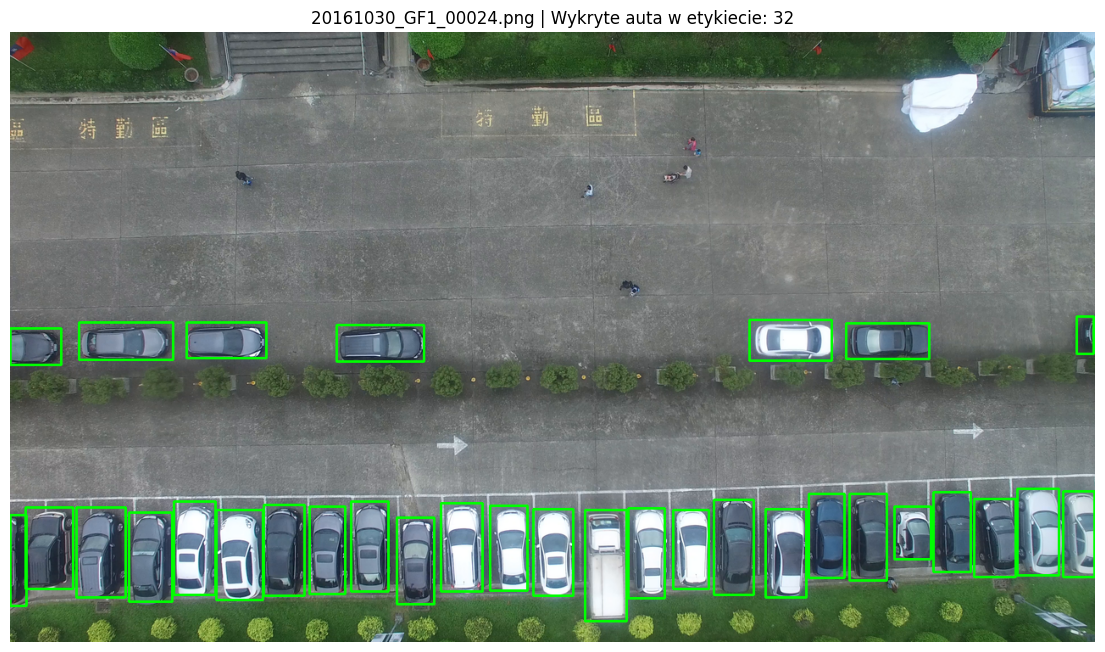

In [ ]:
import os
import glob
import random
import cv2
import matplotlib.pyplot as plt

# Używamy zdefiniowanej wcześniej zmiennej base_dir zamiast nieistniejącej zmiennej path
target_path = base_dir if 'base_dir' in locals() else "/root/.cache/kagglehub/datasets/huynhphucthinh/carpk-yolo/versions/5/CarPK/CarPK"

# 1. Pobranie wszystkich obrazów
all_images = glob.glob(f"{target_path}/**/*.png", recursive=True) + glob.glob(f"{target_path}/**/*.jpg", recursive=True)

if not all_images:
    print("Brak obrazów w podanej ścieżce:", target_path)
else:
    # 2. Losowanie innego zdjęcia przy każdym uruchomieniu komórki
    sample_img_path = random.choice(all_images)

    # 3. Precyzyjne wyznaczenie ścieżki do etykiety .txt w folderze labels
    sample_label_path = sample_img_path.replace("/images/", "/labels/")
    sample_label_path = os.path.splitext(sample_label_path)[0] + ".txt"

    print("Obraz:  ", sample_img_path)
    print("Etykieta:", sample_label_path)
    print("Czy etykieta istnieje?:", os.path.exists(sample_label_path))

    img = cv2.imread(sample_img_path)
    h, w, _ = img.shape
    boxes_count = 0

    # 4. Odczyt i nałożenie bounding boxów
    if os.path.exists(sample_label_path):
        with open(sample_label_path, "r") as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 5:
                    x_c, y_c, bw, bh = map(float, parts[1:5])

                    # Konwersja formatu YOLO (znormalizowanego 0-1) na piksele
                    x1 = int((x_c - bw / 2) * w)
                    y1 = int((y_c - bh / 2) * h)
                    x2 = int((x_c + bw / 2) * w)
                    y2 = int((y_c + bh / 2) * h)

                    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
                    boxes_count += 1

    print(f"Narysowano {boxes_count} ramek na zdjęciu.")

    # 5. Wyświetlenie rezultatu
    plt.figure(figsize=(14, 9))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title(f"{os.path.basename(sample_img_path)} | Wykryte auta w etykiecie: {boxes_count}")
    plt.show()